# Churn Model: Gradient Boosting

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, RocCurveDisplay,
)

In [2]:
# ---- Settings ----
TRAIN_PATH = "model_ready_train.csv"
TEST_PATH = "model_ready_test.csv"
TARGET = "churned"
RANDOM_STATE = 42

train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

assert TARGET in train_df.columns, f"Target column '{TARGET}' not found in training data"
assert TARGET in test_df.columns, f"Target column '{TARGET}' not found in test data"

FEATURES = [c for c in train_df.columns if c != TARGET]
assert list(test_df.columns) == list(train_df.columns), "Train and test columns do not match"

# Verify datasets are already imputed (no missing values)
assert train_df[FEATURES].isna().sum().sum() == 0, "Missing values found in training features"
assert test_df[FEATURES].isna().sum().sum() == 0, "Missing values found in test features"

X_train, y_train = train_df[FEATURES], train_df[TARGET]
X_test, y_test = test_df[FEATURES], test_df[TARGET]

print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Churn rate - train: {y_train.mean():.3f}, test: {y_test.mean():.3f}")

Train: (40000, 40), Test: (10000, 40)
Churn rate - train: 0.289, test: 0.289


In [3]:
# Fit Gradient Boosting directly on the preprocessed features (no preprocessing pipeline needed)
model = GradientBoostingClassifier(
    random_state=RANDOM_STATE,  # 42
)

model.fit(X_train, y_train)

GradientBoostingClassifier(random_state=42)

              precision    recall  f1-score   support

           0      0.913     0.979     0.945      7110
           1      0.939     0.771     0.847      2890

    accuracy                          0.919     10000
   macro avg      0.926     0.875     0.896     10000
weighted avg      0.921     0.919     0.917     10000

ROC AUC: 0.928


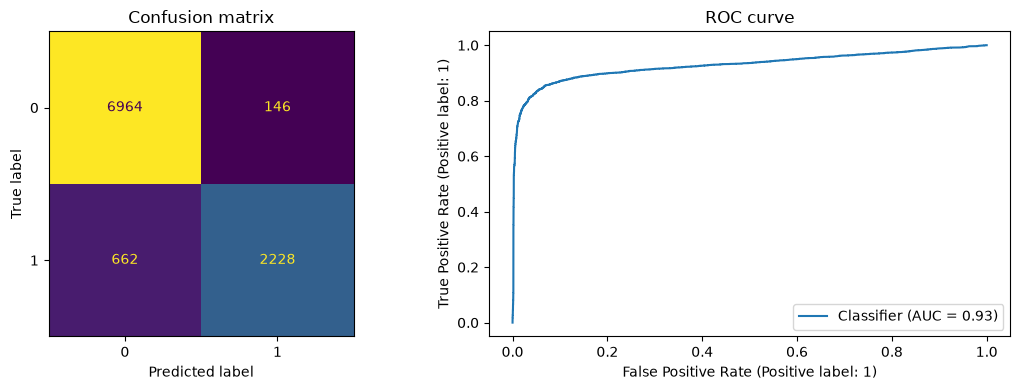

In [4]:
# Evaluate on the held-out test set
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred, digits=3))
print(f"ROC AUC: {roc_auc_score(y_test, y_proba):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred)).plot(ax=axes[0], colorbar=False)
RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[1])
axes[0].set_title("Confusion matrix")
axes[1].set_title("ROC curve")
plt.tight_layout()
plt.show()

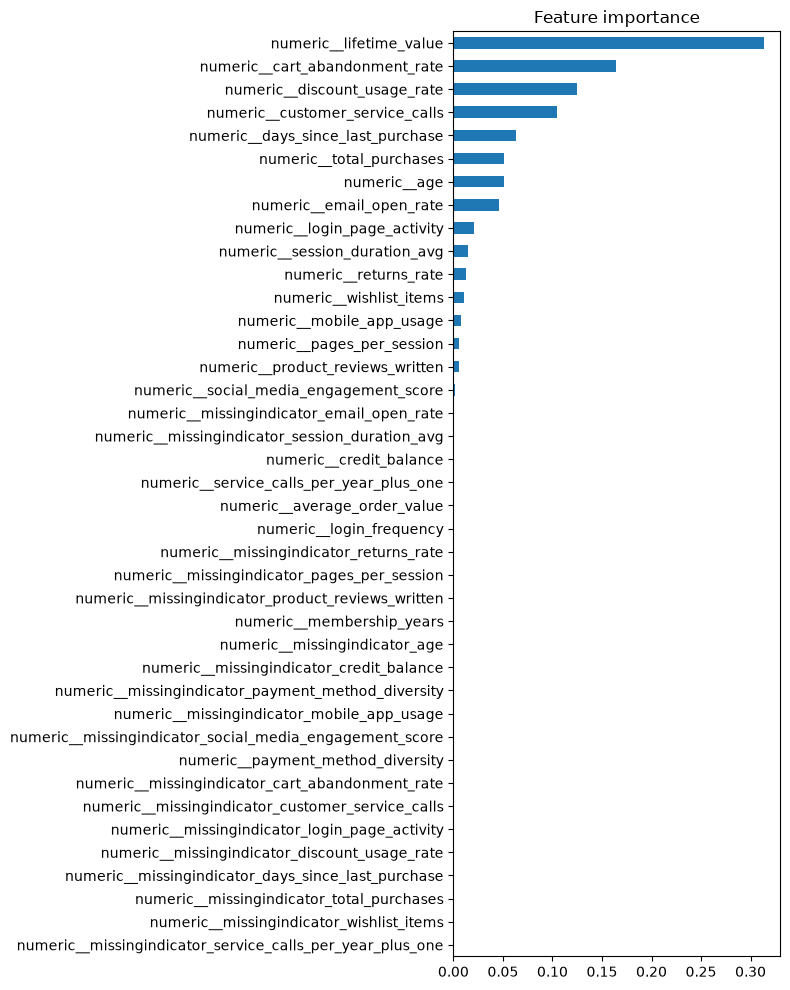

In [5]:
# Feature importance (read directly from the model since no pipeline wrapper is used)
importances = (
    pd.Series(model.feature_importances_, index=FEATURES)
    .sort_values()
)

importances.plot(kind="barh", figsize=(8, 10), title="Feature importance")
plt.tight_layout()
plt.show()

In [6]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [150, 200, 300],
    "learning_rate": [0.05, 0.1, 0.15],
    "max_depth": [3, 4, 5],
    "subsample": [0.8, 1.0],
    "min_samples_leaf": [1, 10, 20],
}

search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=5,
    n_jobs=-1,
)
search.fit(X_train, y_train)

print("Best params:", search.best_params_)
best_model = search.best_estimator_
y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred, digits=3))
print("Best CV ROC AUC:", round(search.best_score_, 3))
print("Test ROC AUC:", round(roc_auc_score(y_test, y_proba), 3))

Best params: {'learning_rate': 0.1, 'max_depth': 3, 'min_samples_leaf': 20, 'n_estimators': 300, 'subsample': 1.0}
              precision    recall  f1-score   support

           0      0.921     0.977     0.948      7110
           1      0.933     0.793     0.857      2890

    accuracy                          0.924     10000
   macro avg      0.927     0.885     0.903     10000
weighted avg      0.924     0.924     0.922     10000

Best CV ROC AUC: 0.926
Test ROC AUC: 0.928
